# Lab 3.7 — Where do the parameters in GPT-2 go?

Assemble a two-block miniature with the same ordering as GPT-2. Read llm_lab/gpt.py alongside the trace. The residual stream keeps its width through every block.

## Follow the final token through two blocks

Each block first normalizes its input and adds an attention update. It normalizes the new stream and adds a feedforward update with a fourfold hidden expansion and GELU activation. The final normalization and a dot product with the token embedding table produce vocabulary scores.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from llm_lab.experiments import record, show

torch.manual_seed(34)
torch.set_num_threads(1)

from llm_lab.gpt import GPT
V, T, D, L = 65, 32, 32, 2
model = GPT(V,T,D,4,L)
ids = torch.tensor([[1,2,3,4]])
with torch.no_grad():
    x = model.wte(ids) + model.wpe(torch.arange(4))
    norms = [x[0,-1].norm().item()]
    for block in model.h:
        x = x + block.attn(block.ln_1(x))
        norms.append(x[0,-1].norm().item())
        x = x + block.mlp(block.ln_2(x))
        norms.append(x[0,-1].norm().item())
    manual = model.ln_f(x) @ model.wte.weight.T
    torch.testing.assert_close(manual, model(ids))
print("Stream / logits:", x.shape, manual.shape)

Stream / logits: torch.Size([1, 4, 32]) torch.Size([1, 4, 65])


## Count before asking PyTorch

Per block, QKV and output projection contribute four square matrices. The MLP contributes eight more squares of parameters. Their biases contribute 9D and the two normalizations add 4D. Weight tying reuses the input table for output scores. Where would another V × D parameters appear if you untied it?

Hand count and PyTorch count: 28576 28576
Out[2]: PosixPath('checkpoints/lab37/miniature.npz')


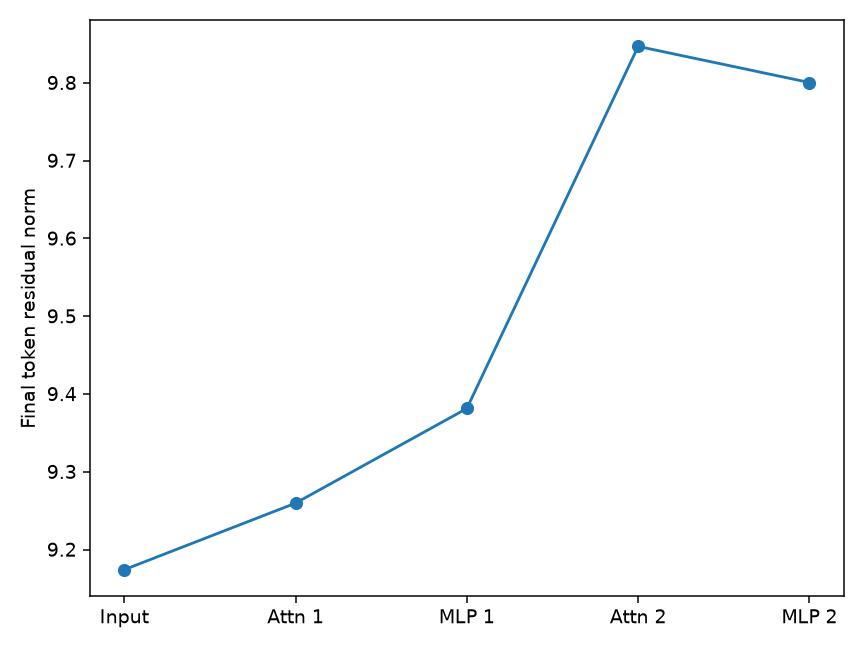

In [2]:
expected = (V+T)*D + L*(12*D**2 + 13*D) + 2*D
actual = sum(p.numel() for p in model.parameters())
assert expected == actual
print("Hand count and PyTorch count:", expected, actual)
plt.plot(["Input","Attn 1","MLP 1","Attn 2","MLP 2"],norms,marker="o")
plt.ylabel("Final token residual norm")
show(37, "residual_trace")
record(37, "miniature", **{k:v.detach() for k,v in model.state_dict().items()})

## Reading the result

At this scale the two independent parameter counts give 28,576. Increasing the number of heads while holding width fixed reshapes the projection outputs. Increasing the number of blocks adds a new set of weights. Which edit would change the hand count? [Original GPT-2 model](https://github.com/openai/gpt-2/blob/master/src/model.py)